In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv('fraudTest.csv')

In [4]:
df

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,...,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,...,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,...,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
555714,555714,2020-12-31 23:59:07,30560609640617,fraud_Reilly and Sons,health_fitness,43.77,Michael,Olson,M,558 Michael Estates,...,40.4931,-91.8912,519,Town planner,1966-02-13,9b1f753c79894c9f4b71f04581835ada,1388534347,39.946837,-91.333331,0
555715,555715,2020-12-31 23:59:09,3556613125071656,fraud_Hoppe-Parisian,kids_pets,111.84,Jose,Vasquez,M,572 Davis Mountains,...,29.0393,-95.4401,28739,Futures trader,1999-12-27,2090647dac2c89a1d86c514c427f5b91,1388534349,29.661049,-96.186633,0
555716,555716,2020-12-31 23:59:15,6011724471098086,fraud_Rau-Robel,kids_pets,86.88,Ann,Lawson,F,144 Evans Islands Apt. 683,...,46.1966,-118.9017,3684,Musician,1981-11-29,6c5b7c8add471975aa0fec023b2e8408,1388534355,46.658340,-119.715054,0
555717,555717,2020-12-31 23:59:24,4079773899158,fraud_Breitenberg LLC,travel,7.99,Eric,Preston,M,7020 Doyle Stream Apt. 951,...,44.6255,-116.4493,129,Cartographer,1965-12-15,14392d723bb7737606b2700ac791b7aa,1388534364,44.470525,-117.080888,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555719 entries, 0 to 555718
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Unnamed: 0             555719 non-null  int64  
 1   trans_date_trans_time  555719 non-null  object 
 2   cc_num                 555719 non-null  int64  
 3   merchant               555719 non-null  object 
 4   category               555719 non-null  object 
 5   amt                    555719 non-null  float64
 6   first                  555719 non-null  object 
 7   last                   555719 non-null  object 
 8   gender                 555719 non-null  object 
 9   street                 555719 non-null  object 
 10  city                   555719 non-null  object 
 11  state                  555719 non-null  object 
 12  zip                    555719 non-null  int64  
 13  lat                    555719 non-null  float64
 14  long                   555719 non-nu

In [6]:
df=df.drop('Unnamed: 0',axis=1)

In [7]:
df=df.drop(['lat','long','unix_time','merch_lat','merch_long'],axis=1)

In [8]:
df=df.drop('city_pop',axis=1)

In [9]:
df['Name']=df['first']+" "+df['last']

In [10]:
df=df.drop('Name',axis=1)

In [11]:
df=df.drop(['first','last'],axis=1)

In [12]:
df=df.drop('street',axis=1)

In [13]:
df['Date'] = pd.to_datetime(df['trans_date_trans_time'])


In [14]:
df=df.drop('trans_date_trans_time',axis=1)

In [15]:
df=df.drop('zip',axis=1)

In [16]:
df=df.drop('merchant',axis=1)

In [17]:
df=df.drop(['cc_num','trans_num'],axis=1)

In [18]:
from datetime import datetime
current_year = datetime.now().year
df['dob'] = pd.to_datetime(df['dob'])
df['age'] = current_year - df['dob'].dt.year

In [19]:
df['hour'] = df['Date'].dt.hour
df['day'] = df['Date'].dt.day
df['month'] = df['Date'].dt.month


In [20]:
df=df.drop('dob',axis=1)

In [21]:
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)

In [22]:
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)

In [23]:
df[['hour_sin','month_sin']]

,hour_sin,month_sin
0,1.224647e-16,1.224647e-16
1,1.224647e-16,1.224647e-16
2,1.224647e-16,1.224647e-16
3,1.224647e-16,1.224647e-16
4,1.224647e-16,1.224647e-16
...,...,...
555714,-2.588190e-01,-2.449294e-16
555715,-2.588190e-01,-2.449294e-16
555716,-2.588190e-01,-2.449294e-16
555717,-2.588190e-01,-2.449294e-16


In [24]:
df=df.drop('Date',axis=1)

In [25]:
df=df.drop('job',axis=1)

In [26]:
df

,category,amt,gender,city,state,is_fraud,age,hour,day,month,hour_sin,month_sin
0,personal_care,2.86,M,Columbia,SC,0,57,12,21,6,1.224647e-16,1.224647e-16
1,personal_care,29.84,F,Altonah,UT,0,35,12,21,6,1.224647e-16,1.224647e-16
2,health_fitness,41.28,F,Bellmore,NY,0,55,12,21,6,1.224647e-16,1.224647e-16
3,misc_pos,60.05,M,Titusville,FL,0,38,12,21,6,1.224647e-16,1.224647e-16
4,travel,3.19,M,Falmouth,MI,0,70,12,21,6,1.224647e-16,1.224647e-16
...,...,...,...,...,...,...,...,...,...,...,...,...
555714,health_fitness,43.77,M,Luray,MO,0,59,23,31,12,-2.588190e-01,-2.449294e-16
555715,kids_pets,111.84,M,Lake Jackson,TX,0,26,23,31,12,-2.588190e-01,-2.449294e-16
555716,kids_pets,86.88,F,Burbank,WA,0,44,23,31,12,-2.588190e-01,-2.449294e-16
555717,travel,7.99,M,Mesa,ID,0,60,23,31,12,-2.588190e-01,-2.449294e-16


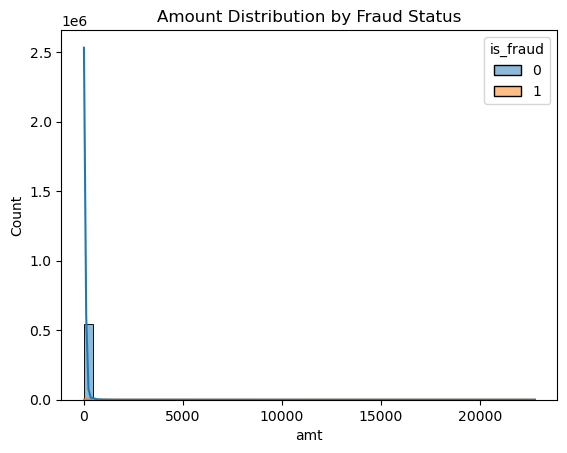

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df, x='amt', hue='is_fraud',kde=True, bins=50)
plt.title('Amount Distribution by Fraud Status')
plt.show()


is_fraud
0    553574
1      2145
Name: count, dtype: int64


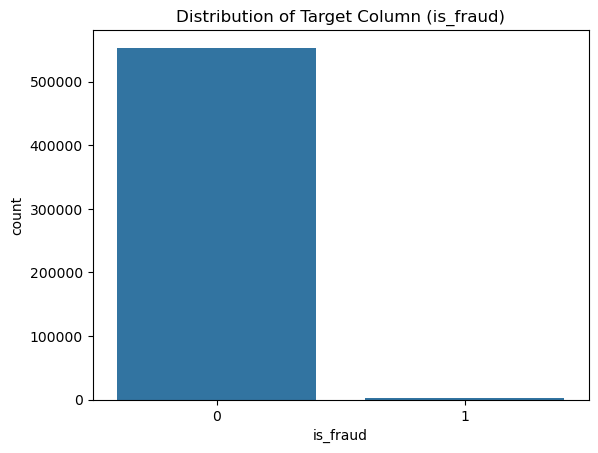

In [28]:
print(df['is_fraud'].value_counts())

sns.countplot(x='is_fraud', data=df)
plt.title('Distribution of Target Column (is_fraud)')
plt.show()  

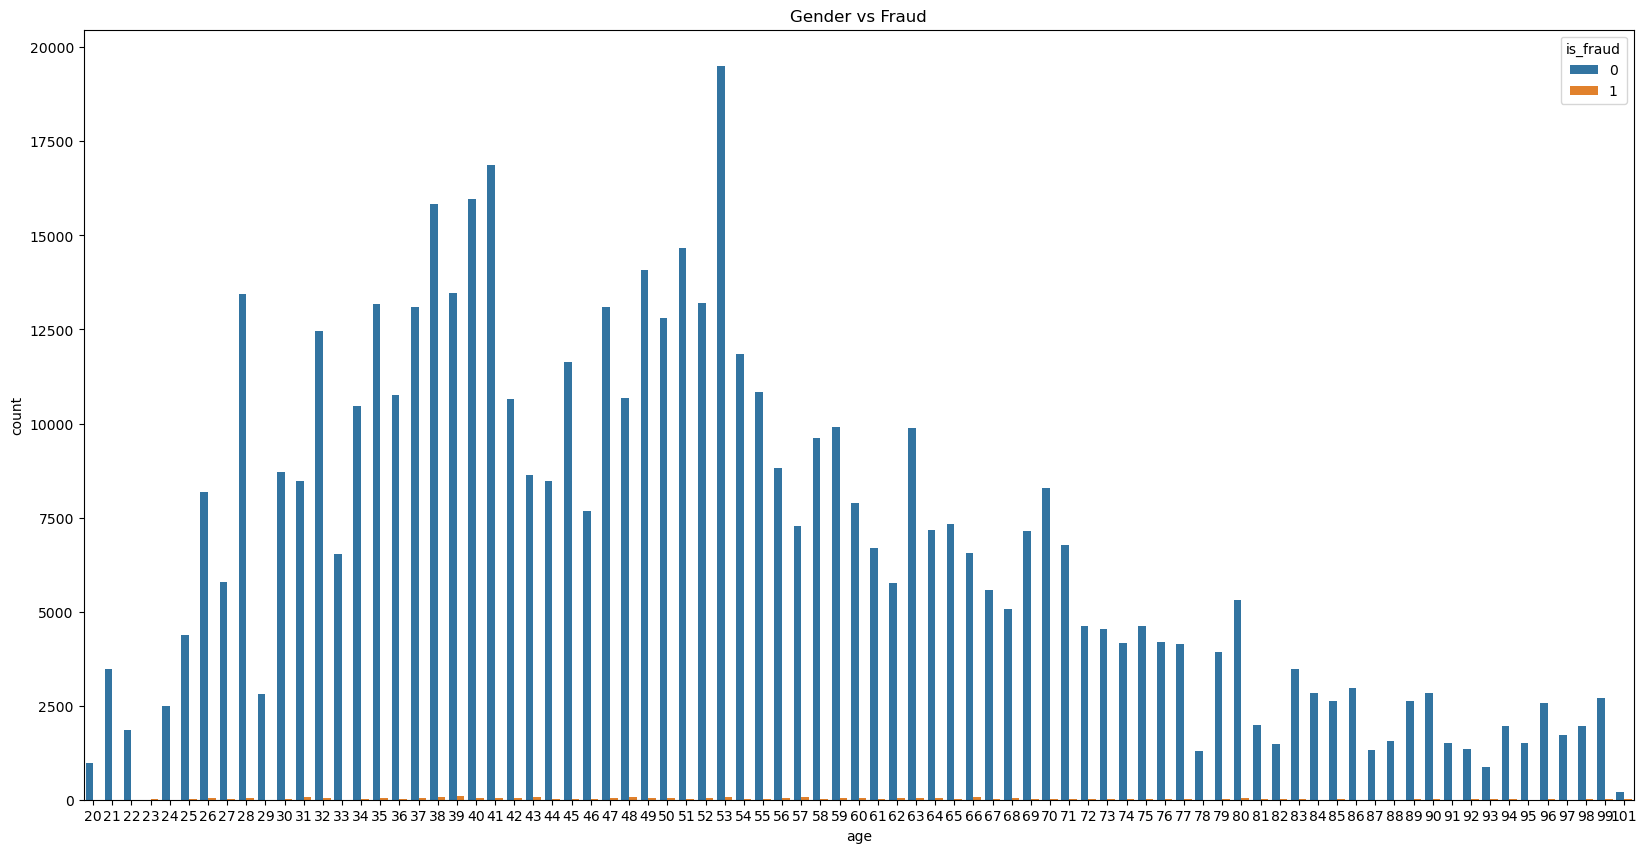

In [32]:
plt.figure(figsize=(20,10))
sns.countplot(x='age', hue='is_fraud', data=df)
plt.title('Gender vs Fraud')
plt.show()

category
shopping_net      0.012111
misc_net          0.009756
grocery_pos       0.009229
shopping_pos      0.004278
gas_transport     0.002732
travel            0.002292
grocery_net       0.002111
misc_pos          0.002082
personal_care     0.001780
entertainment     0.001471
health_fitness    0.001418
food_dining       0.001375
kids_pets         0.001335
home              0.001280
Name: is_fraud, dtype: float64


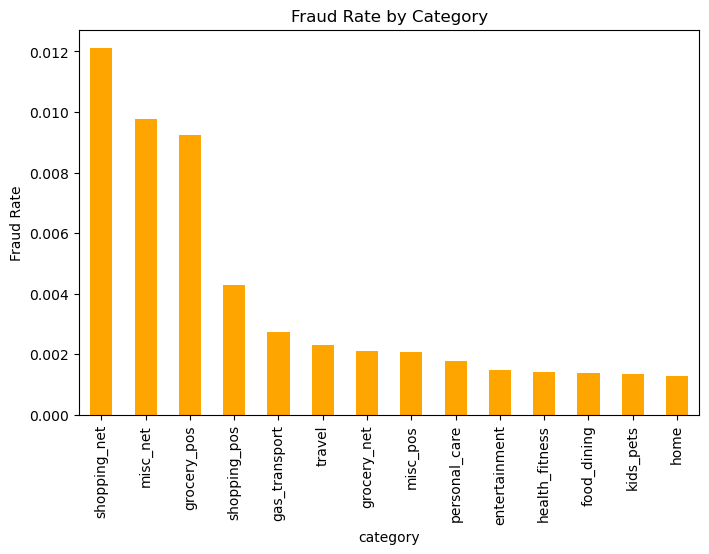

In [33]:
# Fraud rate per category
fraud_rate = df.groupby('category')['is_fraud'].mean().sort_values(ascending=False)
print(fraud_rate)

# Bar plot
fraud_rate.plot(kind='bar', figsize=(8,5), color='orange')
plt.ylabel('Fraud Rate')
plt.title('Fraud Rate by Category')
plt.show()

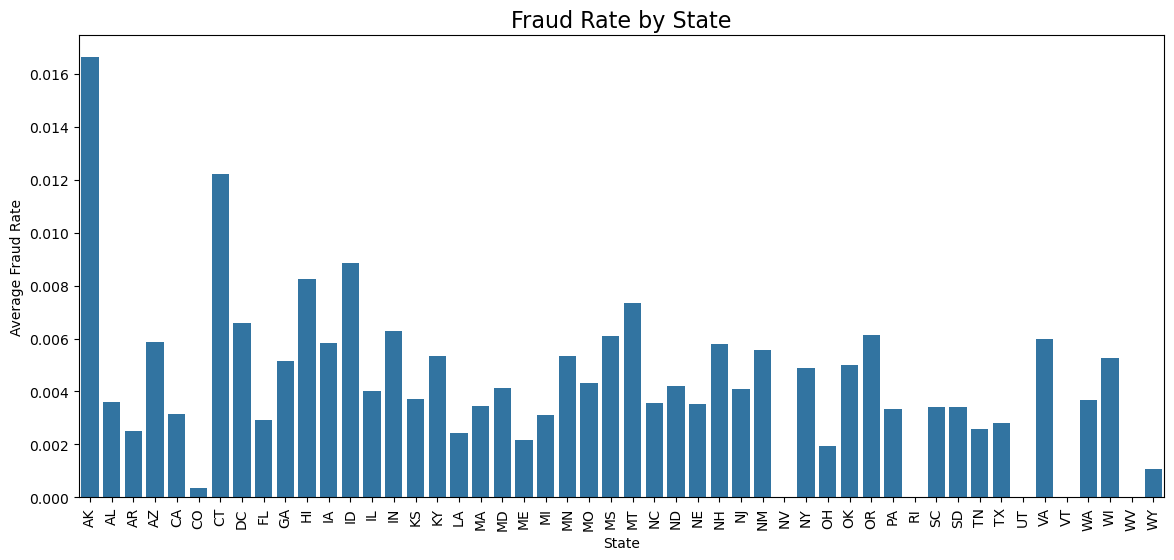

In [34]:
state_fraud = df.groupby('state')['is_fraud'].mean().reset_index()
plt.figure(figsize=(14,6))
sns.barplot(x='state', y='is_fraud', data=state_fraud)
plt.title('Fraud Rate by State', fontsize=16)
plt.xlabel('State')
plt.ylabel('Average Fraud Rate')
plt.xticks(rotation=90)
plt.show()


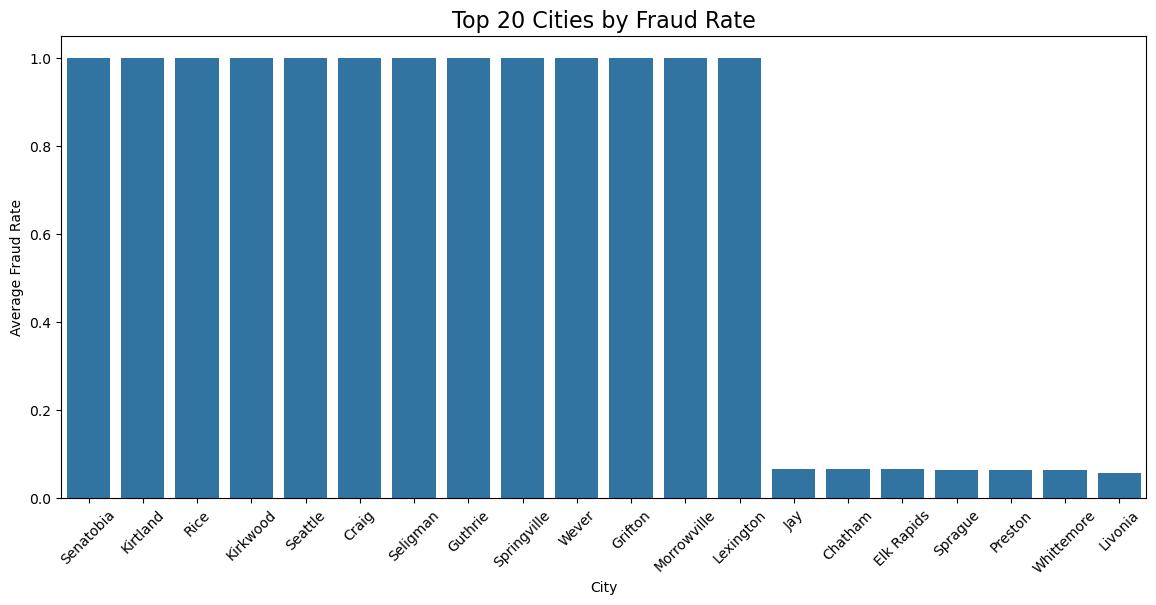

In [35]:
city_fraud = df.groupby('city')['is_fraud'].mean().reset_index().sort_values(by='is_fraud', ascending=False)

plt.figure(figsize=(14,6))
sns.barplot(x='city', y='is_fraud', data=city_fraud.head(20))
plt.title('Top 20 Cities by Fraud Rate', fontsize=16)
plt.xlabel('City')
plt.ylabel('Average Fraud Rate')
plt.xticks(rotation=45)
plt.show()


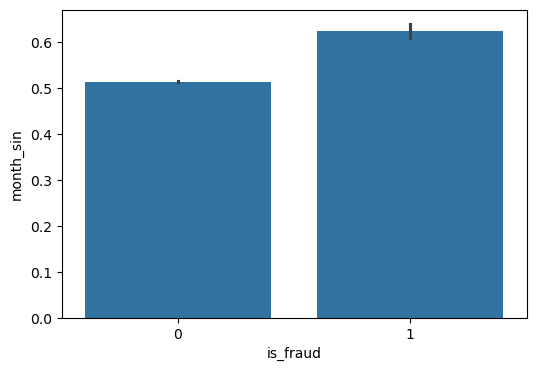

In [36]:
plt.figure(figsize=(6,4))
sns.barplot(x='is_fraud',y=df['month_sin'].abs(),data=df)
plt.xticks(rotation=0)
plt.show()

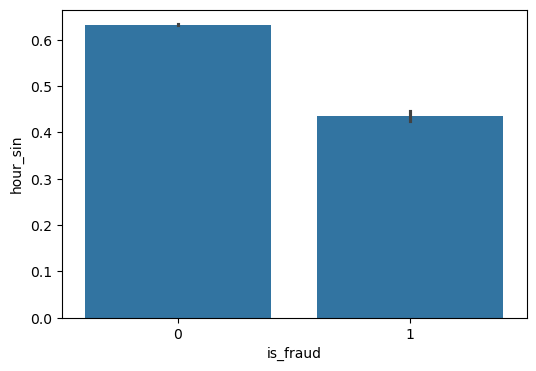

In [37]:
plt.figure(figsize=(6,4))
sns.barplot(x='is_fraud',y=df['hour_sin'].abs(),data=df)
plt.xticks(rotation=0)
plt.show()

In [38]:
category_freq = df['category'].value_counts() / len(df)
df['category_freq'] = df['category'].map(category_freq)
df

,category,amt,gender,city,state,is_fraud,age,hour,day,month,hour_sin,month_sin,category_freq
0,personal_care,2.86,M,Columbia,SC,0,57,12,21,6,1.224647e-16,1.224647e-16,0.070768
1,personal_care,29.84,F,Altonah,UT,0,35,12,21,6,1.224647e-16,1.224647e-16,0.070768
2,health_fitness,41.28,F,Bellmore,NY,0,55,12,21,6,1.224647e-16,1.224647e-16,0.065994
3,misc_pos,60.05,M,Titusville,FL,0,38,12,21,6,1.224647e-16,1.224647e-16,0.062215
4,travel,3.19,M,Falmouth,MI,0,70,12,21,6,1.224647e-16,1.224647e-16,0.031399
...,...,...,...,...,...,...,...,...,...,...,...,...,...
555714,health_fitness,43.77,M,Luray,MO,0,59,23,31,12,-2.588190e-01,-2.449294e-16,0.065994
555715,kids_pets,111.84,M,Lake Jackson,TX,0,26,23,31,12,-2.588190e-01,-2.449294e-16,0.087620
555716,kids_pets,86.88,F,Burbank,WA,0,44,23,31,12,-2.588190e-01,-2.449294e-16,0.087620
555717,travel,7.99,M,Mesa,ID,0,60,23,31,12,-2.588190e-01,-2.449294e-16,0.031399


In [39]:
df=df.drop('category',axis=1)

In [40]:
city_freq = df['city'].value_counts() / len(df)
df['city_freq'] = df['city'].map(city_freq)
df

,amt,gender,city,state,is_fraud,age,hour,day,month,hour_sin,month_sin,category_freq,city_freq
0,2.86,M,Columbia,SC,0,57,12,21,6,1.224647e-16,1.224647e-16,0.070768,0.001152
1,29.84,F,Altonah,UT,0,35,12,21,6,1.224647e-16,1.224647e-16,0.070768,0.001506
2,41.28,F,Bellmore,NY,0,55,12,21,6,1.224647e-16,1.224647e-16,0.065994,0.001931
3,60.05,M,Titusville,FL,0,38,12,21,6,1.224647e-16,1.224647e-16,0.062215,0.001193
4,3.19,M,Falmouth,MI,0,70,12,21,6,1.224647e-16,1.224647e-16,0.031399,0.001603
...,...,...,...,...,...,...,...,...,...,...,...,...,...
555714,43.77,M,Luray,MO,0,59,23,31,12,-2.588190e-01,-2.449294e-16,0.065994,0.001130
555715,111.84,M,Lake Jackson,TX,0,26,23,31,12,-2.588190e-01,-2.449294e-16,0.087620,0.001988
555716,86.88,F,Burbank,WA,0,44,23,31,12,-2.588190e-01,-2.449294e-16,0.087620,0.003009
555717,7.99,M,Mesa,ID,0,60,23,31,12,-2.588190e-01,-2.449294e-16,0.031399,0.001589


In [41]:
category_freq = df['state'].value_counts() / len(df)
df['state_freq'] = df['state'].map(category_freq)
df

,amt,gender,city,state,is_fraud,age,hour,day,month,hour_sin,month_sin,category_freq,city_freq,state_freq
0,2.86,M,Columbia,SC,0,57,12,21,6,1.224647e-16,1.224647e-16,0.070768,0.001152,0.022567
1,29.84,F,Altonah,UT,0,35,12,21,6,1.224647e-16,1.224647e-16,0.070768,0.001506,0.008382
2,41.28,F,Bellmore,NY,0,55,12,21,6,1.224647e-16,1.224647e-16,0.065994,0.001931,0.064633
3,60.05,M,Titusville,FL,0,38,12,21,6,1.224647e-16,1.224647e-16,0.062215,0.001193,0.032578
4,3.19,M,Falmouth,MI,0,70,12,21,6,1.224647e-16,1.224647e-16,0.031399,0.001603,0.035397
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
555714,43.77,M,Luray,MO,0,59,23,31,12,-2.588190e-01,-2.449294e-16,0.065994,0.001130,0.029693
555715,111.84,M,Lake Jackson,TX,0,26,23,31,12,-2.588190e-01,-2.449294e-16,0.087620,0.001988,0.072686
555716,86.88,F,Burbank,WA,0,44,23,31,12,-2.588190e-01,-2.449294e-16,0.087620,0.003009,0.014605
555717,7.99,M,Mesa,ID,0,60,23,31,12,-2.588190e-01,-2.449294e-16,0.031399,0.001589,0.004481


In [42]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['gender']=le.fit_transform(df['gender'])
df

,amt,gender,city,state,is_fraud,age,hour,day,month,hour_sin,month_sin,category_freq,city_freq,state_freq
0,2.86,1,Columbia,SC,0,57,12,21,6,1.224647e-16,1.224647e-16,0.070768,0.001152,0.022567
1,29.84,0,Altonah,UT,0,35,12,21,6,1.224647e-16,1.224647e-16,0.070768,0.001506,0.008382
2,41.28,0,Bellmore,NY,0,55,12,21,6,1.224647e-16,1.224647e-16,0.065994,0.001931,0.064633
3,60.05,1,Titusville,FL,0,38,12,21,6,1.224647e-16,1.224647e-16,0.062215,0.001193,0.032578
4,3.19,1,Falmouth,MI,0,70,12,21,6,1.224647e-16,1.224647e-16,0.031399,0.001603,0.035397
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
555714,43.77,1,Luray,MO,0,59,23,31,12,-2.588190e-01,-2.449294e-16,0.065994,0.001130,0.029693
555715,111.84,1,Lake Jackson,TX,0,26,23,31,12,-2.588190e-01,-2.449294e-16,0.087620,0.001988,0.072686
555716,86.88,0,Burbank,WA,0,44,23,31,12,-2.588190e-01,-2.449294e-16,0.087620,0.003009,0.014605
555717,7.99,1,Mesa,ID,0,60,23,31,12,-2.588190e-01,-2.449294e-16,0.031399,0.001589,0.004481


In [43]:
df=df.drop(['city','state'],axis=1)

In [44]:
df['is_fraud'].value_counts()


is_fraud
0    553574
1      2145
Name: count, dtype: int64

In [46]:
y=df['is_fraud']

In [47]:
X=df.drop('is_fraud',axis=1)

In [48]:
from sklearn.model_selection import train_test_split

In [49]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [50]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", pd.Series(y_res).value_counts())


Before SMOTE: is_fraud
0    387502
1      1501
Name: count, dtype: int64
After SMOTE: is_fraud
0    387502
1    387502
Name: count, dtype: int64


In [51]:
from sklearn.ensemble import RandomForestClassifier

In [52]:
lr=RandomForestClassifier(n_estimators=50,random_state=42,max_depth=12,n_jobs=-1,)

In [53]:
lr.fit(X_train,y_train)

RandomForestClassifier(max_depth=12, n_estimators=50, n_jobs=-1,
                       random_state=42)

In [54]:
y_pred=lr.predict(X_test)

In [55]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


Accuracy: 0.9987523692986876


In [56]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00    166072
           1       0.96      0.70      0.81       644

    accuracy                           1.00    166716
   macro avg       0.98      0.85      0.91    166716
weighted avg       1.00      1.00      1.00    166716



In [57]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [58]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,             
    learning_rate=0.1,       
    scale_pos_weight=1, 
    n_jobs=-1,
    random_state=42
)

In [59]:
xgb.fit(X_res, y_res)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=-1, num_parallel_tree=None, ...)

In [60]:
y_pred = xgb.predict(X_test)

In [61]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    166072
           1       0.68      0.86      0.76       644

    accuracy                           1.00    166716
   macro avg       0.84      0.93      0.88    166716
weighted avg       1.00      1.00      1.00    166716



In [62]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


In [66]:
cm=confusion_matrix(y_pred,y_test)

In [64]:
cm

array([[165808,     89],
       [   264,    555]], dtype=int64)